# 01 — Exploratory Data Analysis

**Goal:** understand how the Turkish day-ahead electricity price (PTF) behaves before modelling it, and set the bar every model has to beat (naive baselines).

Data: hourly PTF, consumption and generation by source (EPİAŞ Transparency Platform), weather for 5 cities (Open-Meteo), Jan 2022 → today. Built by `src/build_dataset.py`.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams.update({"figure.figsize": (12, 4), "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})

ROOT = Path.cwd() if (Path.cwd() / "data").exists() else Path.cwd().parent
df = pd.read_parquet(ROOT / "data" / "processed" / "hourly.parquet")
print(df.shape, df.index.min(), "->", df.index.max())
df[["price", "price_eur", "consumption", "renewable_share"]].describe().round(2)

(42408, 41) 2022-01-01 00:00:00 -> 2026-11-02 23:00:00


,price,price_eur,consumption,renewable_share
count,42408.00,42408.00,42408.00,42408.00
mean,2334.09,79.65,38774.67,0.43
std,989.71,50.54,6461.36,0.13
min,0.00,0.00,19209.20,0.14
25%,1745.00,54.17,33696.32,0.33
50%,2399.99,69.37,38808.48,0.42
75%,2990.00,87.94,43034.51,0.51
max,4800.00,271.63,59503.67,0.84


## 1. Price level over time — TL vs EUR

Prices are set in TL. With high inflation and a weakening lira, the TL price level drifts upward for reasons that have nothing to do with supply and demand. Comparing with the EUR price shows how much of the movement is "real".

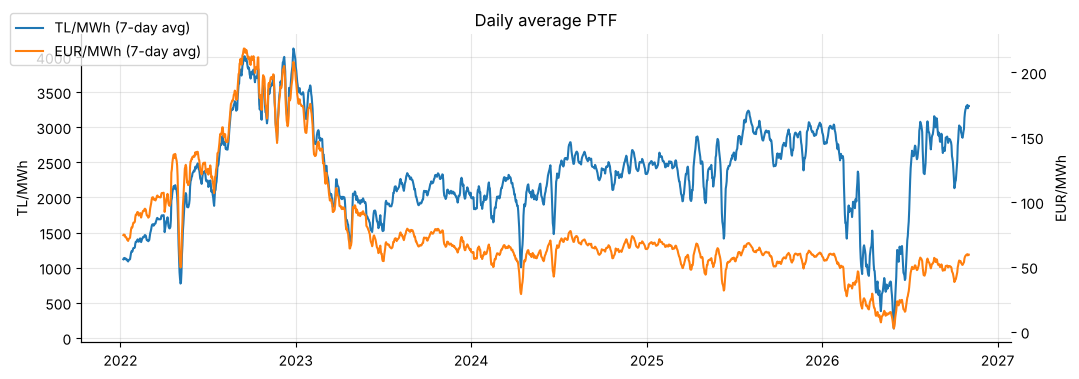

In [2]:
daily = df[["price", "price_eur"]].resample("D").mean()
fig, ax1 = plt.subplots()
ax1.plot(daily.index, daily["price"].rolling(7).mean(), label="TL/MWh (7-day avg)")
ax1.set_ylabel("TL/MWh")
ax2 = ax1.twinx()
ax2.plot(daily.index, daily["price_eur"].rolling(7).mean(), color="tab:orange", label="EUR/MWh (7-day avg)")
ax2.set_ylabel("EUR/MWh"); ax2.grid(False)
fig.legend(loc="upper left", bbox_to_anchor=(0.06, 0.95))
ax1.set_title("Daily average PTF")
plt.show()

## 2. Price cap regimes

The regulator sets a maximum price (*azami uzlaştırma fiyatı*). It shows up in the data as a hard ceiling that changes over time. When many hours sit exactly at the cap, the price is censored — a model can never learn "how high it would have gone". The floor is 0, and there are a surprising number of zero-price hours.

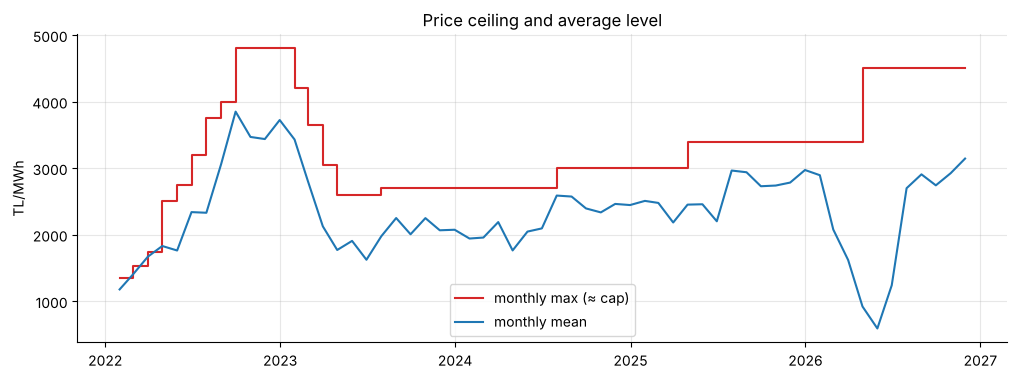

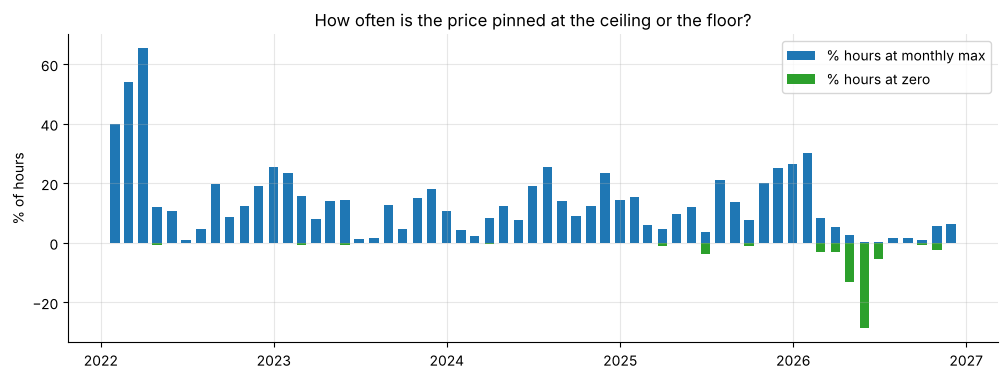

,mean,max,share_at_cap,share_zero
ts,,,,
2025-12-31,2973.04,3400.0,0.27,0.00
2026-01-31,2894.92,3400.0,0.30,0.00
2026-02-28,2078.20,3400.0,0.08,0.03
2026-03-31,1620.32,3400.0,0.05,0.03
2026-04-30,921.06,4500.0,0.03,0.13
2026-05-31,590.90,4500.0,0.00,0.29
2026-06-30,1240.16,4500.0,0.00,0.06
2026-07-31,2699.61,4500.0,0.02,0.00
2026-08-31,2907.81,4500.0,0.02,0.00


In [3]:
monthly = df["price"].resample("ME").agg(
    mean="mean",
    max="max",
    share_at_cap=lambda x: (x >= x.max() - 0.01).mean(),
    share_zero=lambda x: (x <= 0.01).mean(),
)
fig, ax = plt.subplots()
ax.step(monthly.index, monthly["max"], where="post", label="monthly max (≈ cap)", color="tab:red")
ax.plot(monthly.index, monthly["mean"], label="monthly mean")
ax.set_ylabel("TL/MWh"); ax.set_title("Price ceiling and average level"); ax.legend()
plt.show()

fig, ax = plt.subplots()
ax.bar(monthly.index, monthly["share_at_cap"] * 100, width=20, label="% hours at monthly max")
ax.bar(monthly.index, -monthly["share_zero"] * 100, width=20, label="% hours at zero", color="tab:green")
ax.set_ylabel("% of hours"); ax.set_title("How often is the price pinned at the ceiling or the floor?"); ax.legend()
plt.show()
monthly.tail(12).round(2)

In [4]:
zero = df["price"] <= 0.01
print(f"Zero-price hours overall: {zero.mean():.1%}")
print("Zero-price hours by year:")
print(zero.groupby(df.index.year).mean().map("{:.1%}".format))
print("\nZero-price hours by hour of day (top 8):")
print(zero.groupby(df.index.hour).mean().sort_values(ascending=False).head(8).map("{:.1%}".format))

Zero-price hours overall: 1.1%
Zero-price hours by year:
ts
2022    0.1%
2023    0.1%
2024    0.0%
2025    0.5%
2026    5.6%
Name: price, dtype: str

Zero-price hours by hour of day (top 8):
ts
12    4.2%
13    3.7%
11    3.3%
10    3.1%
14    2.8%
9     2.4%
15    2.4%
8     1.4%
Name: price, dtype: str


## 3. Daily and weekly shape

Electricity price follows people (and the sun). Solar generation now pushes midday prices down, especially in spring.

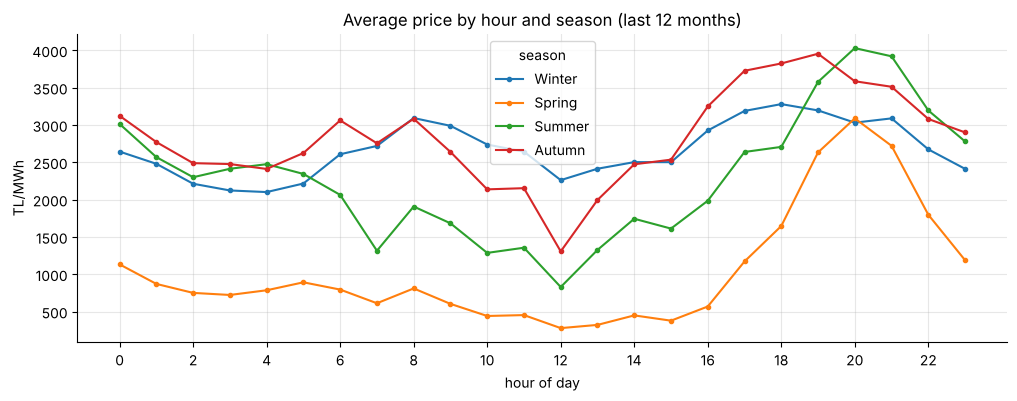

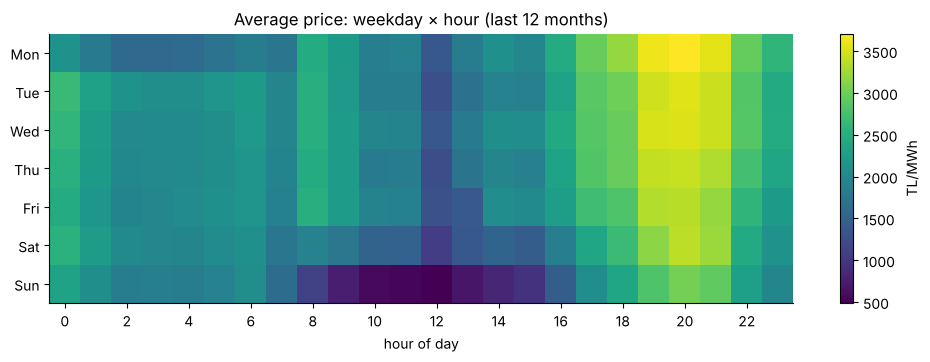

In [5]:
last_year = df.loc[df.index >= df.index.max() - pd.Timedelta(days=365)]
season = last_year.index.month.map({12: "Winter", 1: "Winter", 2: "Winter", 3: "Spring", 4: "Spring", 5: "Spring",
                                     6: "Summer", 7: "Summer", 8: "Summer", 9: "Autumn", 10: "Autumn", 11: "Autumn"})
profile = last_year.groupby([season, last_year.index.hour])["price"].mean().unstack(0)
profile[["Winter", "Spring", "Summer", "Autumn"]].plot(marker=".")
plt.legend(title="season"); plt.xlabel("hour of day"); plt.ylabel("TL/MWh"); plt.title("Average price by hour and season (last 12 months)")
plt.xticks(range(0, 24, 2)); plt.show()

days = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
heat = last_year.groupby([last_year.index.dayofweek, last_year.index.hour])["price"].mean().unstack()
fig, ax = plt.subplots(figsize=(12, 3.5))
im = ax.imshow(heat, aspect="auto", cmap="viridis")
ax.set_yticks(range(7), days); ax.set_xticks(range(0, 24, 2)); ax.set_xlabel("hour of day")
ax.set_title("Average price: weekday × hour (last 12 months)"); fig.colorbar(im, label="TL/MWh"); ax.grid(False)
plt.show()

## 4. What drives the price?

Two obvious candidates: **demand** (consumption) and **cheap supply** (hydro, wind, solar push expensive gas plants out of the merit order).

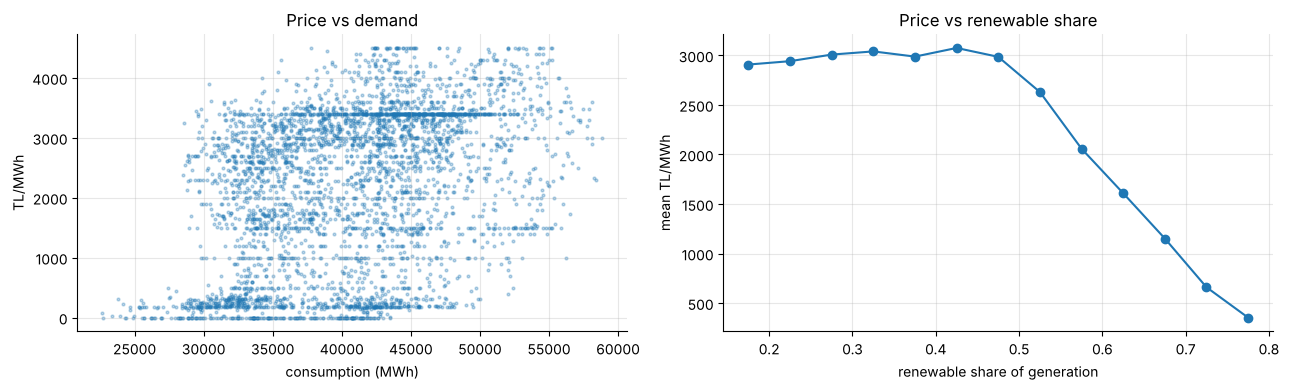

renewable_share             -0.59
wind_solar_share            -0.38
sun                         -0.24
wind_speed_100m_canakkale   -0.09
temperature_2m_istanbul      0.01
wind                         0.03
dammedHydro                  0.05
consumption                  0.42
naturalGas                   0.66
Name: price, dtype: float64

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sample = last_year.sample(4000, random_state=0)
axes[0].scatter(sample["consumption"], sample["price"], s=4, alpha=0.3)
axes[0].set_xlabel("consumption (MWh)"); axes[0].set_ylabel("TL/MWh"); axes[0].set_title("Price vs demand")

bins = pd.cut(last_year["renewable_share"], np.arange(0.1, 0.95, 0.05))
binned = last_year.groupby(bins, observed=True)["price"].agg(["mean", "count"])
binned = binned[binned["count"] > 50]
axes[1].plot([b.mid for b in binned.index], binned["mean"], marker="o")
axes[1].set_xlabel("renewable share of generation"); axes[1].set_ylabel("mean TL/MWh")
axes[1].set_title("Price vs renewable share")
plt.tight_layout(); plt.show()

corr_cols = ["price", "consumption", "renewable_share", "wind_solar_share", "naturalGas", "dammedHydro",
             "wind", "sun", "temperature_2m_istanbul", "wind_speed_100m_canakkale"]
last_year[corr_cols].corr(method="spearman")["price"].drop("price").sort_values().round(2)

## 5. What is known at forecast time? (avoiding leakage)

Timeline for forecasting day **D**:

| When | What happens |
|---|---|
| D-2, ~14:00 | PTF for D-1 is published |
| **D-1, morning** | **we make the forecast for D** |
| D-1, ~14:00 | PTF for D is published → we can score yesterday's forecast the day after |

So at forecast time we know: all prices up to the end of D-1, realised consumption/generation up to roughly the morning of D-1, and *weather forecasts* for D. Using realised D weather or D generation in training would be leakage.

That means "same hour yesterday" (lag 24h) is a legitimate baseline: yesterday's (D-1) prices are already published.

## 6. Naive baselines — the bar to beat

In [7]:
eval_start = df.index.max() - pd.Timedelta(days=365)
y = df["price"]
baselines = pd.DataFrame({
    "actual": y,
    "same hour yesterday (D-1)": y.shift(24),
    "same hour last week (D-7)": y.shift(168),
    "avg of D-1 and D-7": (y.shift(24) + y.shift(168)) / 2,
}).loc[eval_start:]

def scores(pred, actual):
    err = pred - actual
    return pd.Series({"MAE": err.abs().mean(), "RMSE": np.sqrt((err ** 2).mean()),
                      "MAE % of mean price": err.abs().mean() / actual.mean() * 100})

results = pd.DataFrame({c: scores(baselines[c], baselines["actual"]) for c in baselines.columns[1:]}).T
print(f"Evaluation window: {baselines.index.min().date()} -> {baselines.index.max().date()} ({len(baselines):,} hours)")
results.round(1)

Evaluation window: 2025-11-02 -> 2026-11-02 (8,761 hours)


,MAE,RMSE,MAE % of mean price
same hour yesterday (D-1),520.0,807.0,23.6
same hour last week (D-7),606.1,908.0,27.5
avg of D-1 and D-7,478.4,696.8,21.7


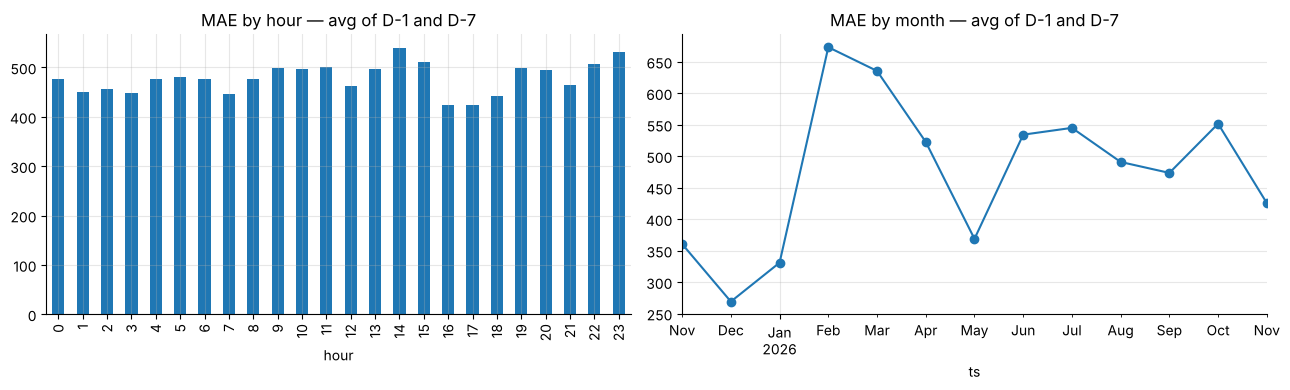

In [8]:
best = results["MAE"].idxmin()
by_hour = (baselines[best] - baselines["actual"]).abs().groupby(baselines.index.hour).mean()
by_month = (baselines[best] - baselines["actual"]).abs().resample("ME").mean()

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
by_hour.plot(kind="bar", ax=axes[0]); axes[0].set_title(f"MAE by hour — {best}"); axes[0].set_xlabel("hour")
by_month.plot(marker="o", ax=axes[1]); axes[1].set_title(f"MAE by month — {best}")
plt.tight_layout(); plt.show()

## 7. Takeaways

**1. Price level — TL vs EUR.** In the short run TL and EUR prices move together, so day-to-day changes reflect real market conditions. In the long run they diverge: since 2023 the TL price has risen while the EUR price has stayed flat or fallen. Most of the TL increase comes from inflation and currency depreciation, not from the electricity market. The model has to account for this slow drift (e.g. by working with recent price levels or relative changes rather than absolute TL values).

**2. Price cap regimes and zero prices.** The regulator's price ceiling is clearly visible and has changed several times: about 4,800 TL/MWh in late 2022, 2,600–2,700 in 2023, 3,000 in mid-2024, 3,400 in 2025 and 4,500 in 2026. In some months a large share of hours sits exactly at the ceiling (up to 40–65% in early 2022, ~30% in winter 2025–26), which means the price is censored: we never see how high it would have gone. At the other end, zero-price hours were almost non-existent before 2025 but reached 5.6% of hours in 2026 and 29% in May 2026, concentrated around midday. Strong hydro and solar output in spring now regularly pushes the price to the floor.

**3. Where forecasting is hard.** The baseline error is fairly flat across hours (≈420–540 TL/MWh), slightly higher around midday and late evening. The month-to-month picture is more revealing: the error is lowest in Dec 2025–Jan 2026 (≈270–330), when many hours were pinned at the cap and prices were stable, and highest in Feb–Mar 2026 (≈630–670), when the market moved from cap-bound winter prices to the spring collapse. Regime transitions, not specific hours, are the hardest part. The strongest single driver is the renewable share of generation (Spearman −0.59): above ~50% renewables the price drops steeply, while gas generation moves with price (+0.66).

**4. The bar to beat.** Over the last 12 months the best naive baseline, the average of the same hour yesterday and the same hour last week, has an MAE of **478 TL/MWh (21.7% of the mean price)**. Yesterday's price alone gives 520 TL/MWh. Any model in notebook 02 must clearly beat 478 TL/MWh to be worth using.